# 04 — Plan d'expériences numérique et recalage sur données

**Partie A — DOE** : facteurs pression de gonflage (60–200 kPa), largeur (0,45–0,85 m, rapport d'aspect
65 %), charge (20–45 kN), type de sol (3 niveaux). Réponses : DP/W à 15 % de glissement, rendement,
enfoncement, coefficient de résistance au roulement, énergie de frottement sur route (indice d'usure).

**Partie B — Recalage** des paramètres de cisaillement $(c, \varphi, K)$ par moindres carrés non
linéaires (`scipy.optimize.least_squares`).

> ⚠️ **Données** : aucune courbe traction/glissement expérimentale n'a pu être récupérée sous forme
> numérique. Le fichier `data/experimental/DEMO_brixius_pseudo_mesures.csv` contient des
> **pseudo-mesures de démonstration** générées par la corrélation empirique de **Brixius (1987)**
> (+ bruit). Ce ne sont **pas** des mesures ; la démarche est identique avec de vraies données.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from agritire import plotting
plotting.setup()
pd.set_option("display.precision", 3)

from agritire.doe import (full_factorial, latin_hypercube, run_plan, main_effects, sensitivity_table,
                          FACTORS, SOIL_LEVELS, DEFLECTION_LIMIT)
import time

## A1. Plan factoriel complet 3³ × 3 sols (81 calculs)

In [2]:
t0 = time.time()
ff = run_plan(full_factorial(levels=3))
print(f"{len(ff)} calculs en {time.time()-t0:.1f} s ; modes : {ff['mode'].value_counts().to_dict()}")
print(f"configurations hors domaine réaliste (écrasement route > {DEFLECTION_LIMIT:.0%} de la hauteur de flanc) : {(~ff.feasible).sum()}")
ff[~ff.feasible][["inflation", "width", "load", "soil", "road_deflection_ratio"]].drop_duplicates(["inflation", "width", "load"])

81 calculs en 0.3 s ; modes : {'flexible': 59, 'rigid': 22}
configurations hors domaine réaliste (écrasement route > 25% de la hauteur de flanc) : 6


,inflation,width,load,soil,road_deflection_ratio
1,60000.0,0.45,32500.0,dry_sand,0.385
2,60000.0,0.45,45000.0,dry_sand,0.738


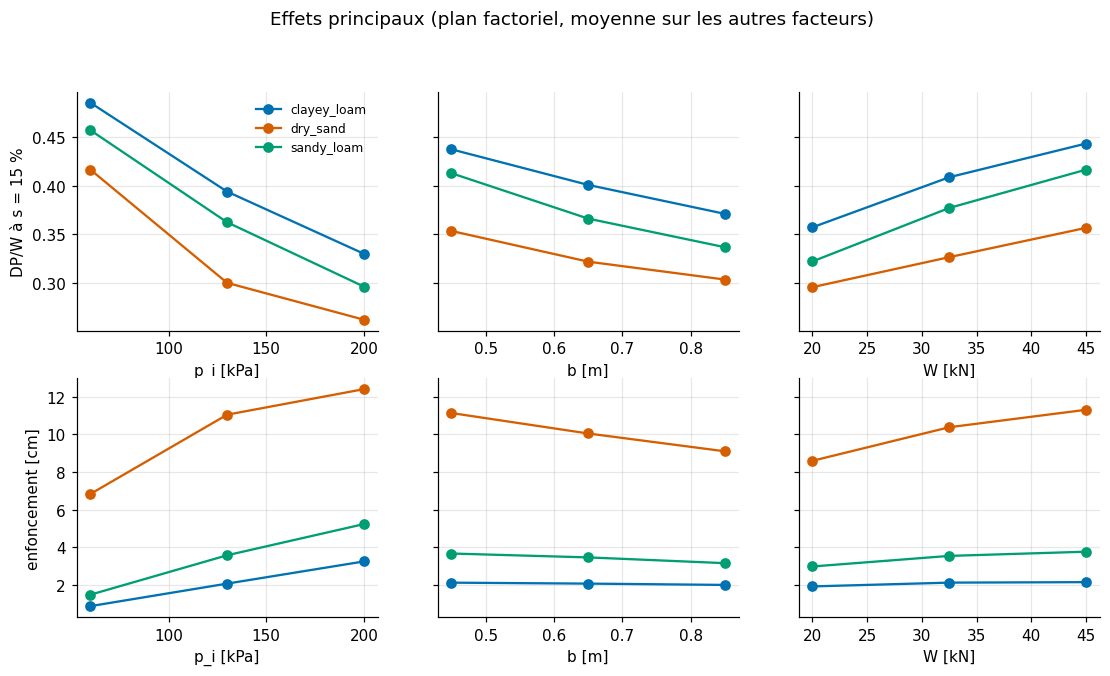

In [3]:
labels = {"inflation": "p_i [kPa]", "width": "b [m]", "load": "W [kN]"}
conv = {"inflation": 1e-3, "width": 1.0, "load": 1e-3}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2), sharey="row")
for row, resp, ylab in ((0, "ntr", "DP/W à s = 15 %"), (1, "sinkage", "enfoncement [cm]")):
    for ax, f in zip(axes[row], FACTORS):
        for soil, grp in ff.groupby("soil"):
            me = grp.groupby(f)[resp].mean()
            yv = me.values * (100 if resp == "sinkage" else 1)
            ax.plot(me.index * conv[f], yv, "o-", label=soil)
        ax.set_xlabel(labels[f])
    axes[row][0].set_ylabel(ylab)
axes[0][0].legend(fontsize=8)
fig.suptitle("Effets principaux (plan factoriel, moyenne sur les autres facteurs)", y=1.0)
plotting.save(fig, "04_effets_principaux");

- La **pression** est le levier principal sur l'enfoncement et la traction (cohérent avec la pratique
  du « basse pression » au champ).
- La **charge** augmente l'enfoncement et, à pression fixée, augmente légèrement DP/W : l'aire de
  contact croît avec la charge alors que la résistance de compaction ne dépend que de $p_g$ en mode
  souple. Les essais réels (et la corrélation de Brixius, partie B) montrent plutôt l'inverse, car la
  pression y est ajustée à la charge et la pression au sol réelle n'est pas uniforme : c'est une limite
  du modèle à pression de contact uniforme.
- La **largeur**, à pression fixée, a un effet faible voire défavorable : même enfoncement mais ornière
  plus large ($R_c \propto b$). Dans ce modèle, l'intérêt d'un pneu large passe **par la pression plus
  basse qu'il autorise** pour une même charge (tables charge/pression), pas par la largeur seule. Les
  deux facteurs sont donc couplés en pratique, alors que le DOE les traite comme indépendants : point à
  garder en tête en lisant les sensibilités.

## A2. Hypercube latin (100 points par sol) et analyse de sensibilité

In [4]:
t0 = time.time()
lhs = run_plan(latin_hypercube(100, seed=0))
print(f"{len(lhs)} calculs en {time.time()-t0:.1f} s")
sens = sensitivity_table(lhs)
piv = sens.pivot_table(index=["response", "soil"], columns="factor", values=["SRC", "R2"]).round(2)
piv[[("SRC", "inflation"), ("SRC", "width"), ("SRC", "load"), ("R2", "load")]].rename(columns={("R2", "load"): ("R²", "")})

300 calculs en 1.3 s


SRC                R2
factor                  inflation width  load  load
response    soil                                   
efficiency  clayey_loam     -0.85 -0.29  0.39  0.92
            dry_sand        -0.80 -0.19  0.14  0.77
            sandy_loam      -0.89 -0.31  0.31  0.96
ntr         clayey_loam     -0.81 -0.37  0.49  0.98
            dry_sand        -0.75 -0.27  0.25  0.79
            sandy_loam      -0.78 -0.42  0.47  0.98
road_energy clayey_loam     -0.00  0.00  1.00  1.00
            dry_sand         0.00 -0.00  1.00  1.00
            sandy_loam      -0.00  0.00  1.00  1.00
rr_coeff    clayey_loam      0.88  0.27 -0.36  0.94
            dry_sand         0.81  0.15 -0.09  0.75
            sandy_loam       0.92  0.27 -0.25  0.96
sinkage     clayey_loam      0.99  0.00  0.03  0.99
            dry_sand         0.74 -0.30  0.42  0.74
            sandy_loam       0.98 -0.03  0.10  0.97

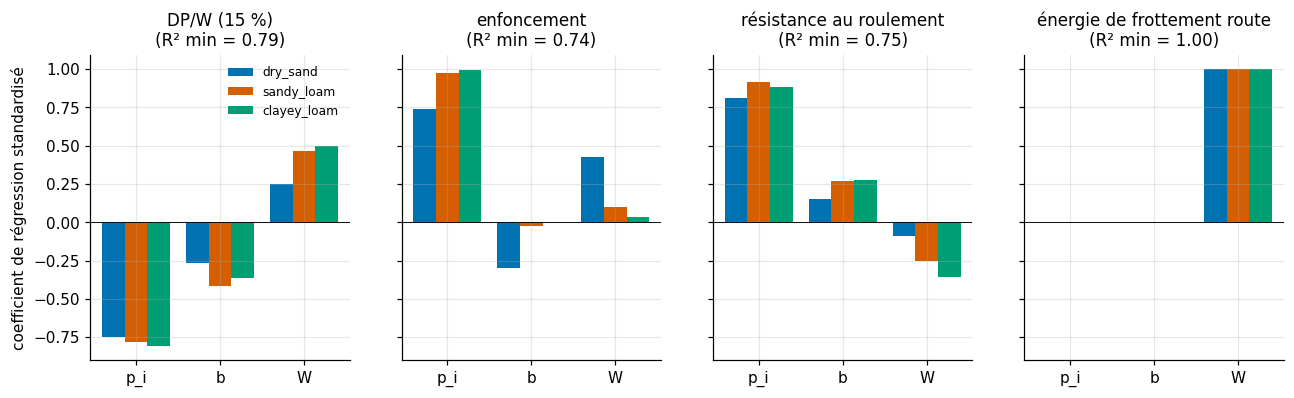

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, resp, title in zip(axes, ["ntr", "sinkage", "rr_coeff", "road_energy"],
                            ["DP/W (15 %)", "enfoncement", "résistance au roulement", "énergie de frottement route"]):
    sub = sens[sens.response == resp]
    x = np.arange(len(FACTORS)); wbar = 0.27
    for i, soil in enumerate(SOIL_LEVELS):
        vals = sub[sub.soil == soil].set_index("factor").loc[list(FACTORS), "SRC"]
        ax.bar(x + (i - 1) * wbar, vals, wbar, label=soil)
    r2 = sub.groupby("soil").R2.first().min()
    ax.set_xticks(x, ["p_i", "b", "W"]); ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"{title}\n(R² min = {r2:.2f})")
axes[0].set_ylabel("coefficient de régression standardisé"); axes[0].legend(fontsize=8)
plotting.save(fig, "04_sensibilites_SRC");

Les SRC donnent le poids relatif de chaque facteur **sur la plage étudiée** ; ils ne sont fiables que
si le modèle linéaire explique l'essentiel de la variance ($R^2$ affiché). Un $R^2$ plus faible signale
des non-linéarités / interactions (ex. changement de mode souple → rigide) : il faudrait alors une
méthode globale (indices de Sobol). Les corrélations de rang de Spearman (dans `sens`) confirment le
sens des effets.

L'énergie de frottement sur route ne dépend pas du sol et, dans ce modèle, elle ne dépend **que** de la
charge (SRC = 1) : avec $F_x = 0{,}1\,W$ et $C_s/F_z$ fixé, $E_f = F_x\,s$ où $s$ ne dépend que de
$F_x/F_z$, donc $E_f \propto W$. Pression et largeur n'ont aucun effet par construction (voir
notebook 02) : la sensibilité de l'usure à la pression ne pourra être étudiée qu'avec une rigidité de
glissement $C_s(p_i, W)$ mesurée.

## B1. Données de démonstration

In [6]:
from pathlib import Path
from agritire.calibration import load_dataset, fit_soil, predict, brixius_net_traction
from agritire.soil import SOILS
from agritire.terramechanics import Tire
tire = Tire()
data = load_dataset(Path("..") / "data" / "experimental" / "DEMO_brixius_pseudo_mesures.csv")
print(data.source.unique())
data.head()

['DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL']


,load,inflation,slip,net_traction_ratio,source
0,20000,80000,0.03,0.144,DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL
1,20000,80000,0.05,0.217,DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL
2,20000,80000,0.08,0.359,DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL
3,20000,80000,0.11,0.453,DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL
4,20000,80000,0.14,0.482,DEMO_Brixius1987_plus_bruit_NON_EXPERIMENTAL


## B2. Vérification de la procédure : retrouver des paramètres connus
On génère des données **avec notre propre modèle** (paramètres « vrais » connus) + bruit de même niveau
(σ = 0,015), puis on recale. Si l'on ne retrouve pas les paramètres ici, il est inutile d'aller plus loin.

In [7]:
base = SOILS["sandy_loam"]
truth = base.with_(c=8.0, phi_deg=27.0, K=0.03)
rng = np.random.default_rng(1)
synth = data.copy()
synth["net_traction_ratio"] = predict(truth, tire, data) + rng.normal(0, 0.015, len(data))
fit_v = fit_soil(synth, tire, base)
pd.DataFrame({"vrai": [truth.c, truth.phi_deg, truth.K], "recalé": fit_v.params.values,
              "écart-type": fit_v.std_errors.values}, index=fit_v.params.index).assign(
    ecart_en_sigma=lambda d: (d["recalé"] - d["vrai"]) / d["écart-type"])

,vrai,recalé,écart-type,ecart_en_sigma
c,8.00,11.073,2.367,1.298
phi_deg,27.00,25.382,0.921,-1.757
K,0.03,0.029,0.001,-0.755


Les paramètres sont retrouvés à environ 1–2 écarts-types : la procédure (modèle + optimiseur + estimation
d'incertitude) est **vérifiée**.

## B3. Identifiabilité : pourquoi il faut plusieurs couples charge/pression
Si toutes les mesures sont faites **à pression constante**, l'aire de contact $A = W/p_g$ est
proportionnelle à la charge, et la poussée maximale $cA + W\tan\varphi = W\,(c/p_g + \tan\varphi)$ ne
permet pas de séparer $c$ et $\varphi$.

In [8]:
same_p = synth.copy(); same_p["inflation"] = 120e3
same_p["net_traction_ratio"] = predict(truth, tire, same_p) + rng.normal(0, 0.015, len(same_p))
fit_same = fit_soil(same_p, tire, base)
print("corrélation c–φ, pression constante  :", round(fit_same.correlation.loc["c", "phi_deg"], 3))
print("corrélation c–φ, pression ∝ charge   :", round(fit_v.correlation.loc["c", "phi_deg"], 3))
print("écarts-types (pression constante) :", fit_same.std_errors.round(3).to_dict())

corrélation c–φ, pression constante  : -0.994
corrélation c–φ, pression ∝ charge   : -0.82
écarts-types (pression constante) : {'c': 14.082, 'phi_deg': 5.366, 'K': 0.001}


Avec une pression unique, $c$ et $\varphi$ sont presque parfaitement corrélés (incertitudes énormes).
**Le plan d'essais conditionne ce qu'on peut identifier** : c'est un argument pour concevoir la campagne
expérimentale en même temps que le modèle.

## B4. Confrontation à la référence empirique de Brixius (pseudo-mesures)

In [9]:
fit_free = fit_soil(data, tire, base)
fit_bnd = fit_soil(data, tire, base, bounds={"c": (0.0, 25.0)})
tab = pd.DataFrame({
    "Wong (tableau)": [base.c, base.phi_deg, base.K, np.nan, np.nan],
    "recalage libre": [*fit_free.params.values, fit_free.rmse, fit_free.r2],
    "± (1σ)": [*fit_free.std_errors.values, np.nan, np.nan],
    "recalage c ≤ 25 kPa": [*fit_bnd.params.values, fit_bnd.rmse, fit_bnd.r2],
}, index=["c [kPa]", "φ [°]", "K [m]", "RMSE", "R²"])
tab

,Wong (tableau),recalage libre,± (1σ),recalage c ≤ 25 kPa
c [kPa],1.72,59.698,5.682,25.000
φ [°],29.00,25.085,1.922,34.583
K [m],0.02,0.039,0.003,0.035
RMSE,NaN,0.023,NaN,0.039
R²,NaN,0.984,NaN,0.954


,c,phi_deg,K
c,1.00,-0.72,0.48
phi_deg,-0.72,1.00,0.24
K,0.48,0.24,1.00


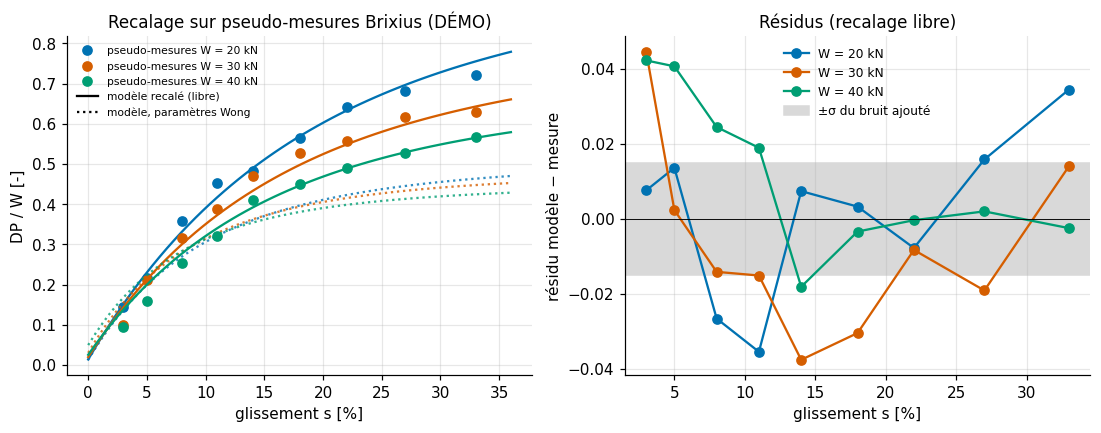

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sfine = np.linspace(0.0, 0.36, 60)
for i, (W, grp) in enumerate(data.groupby("load")):
    col = plotting.COLORS[i]
    axes[0].plot(100 * grp.slip, grp.net_traction_ratio, "o", color=col, label=f"pseudo-mesures W = {W/1e3:.0f} kN")
    curve = pd.DataFrame(dict(load=W, inflation=grp.inflation.iloc[0], slip=sfine))
    axes[0].plot(100 * sfine, predict(fit_free.soil, tire, curve), "-", color=col)
    axes[0].plot(100 * sfine, predict(base, tire, curve), ":", color=col, alpha=0.8)
    axes[1].plot(100 * grp.slip, fit_free.residuals[grp.index], "o-", color=col, label=f"W = {W/1e3:.0f} kN")
axes[0].plot([], [], "k-", label="modèle recalé (libre)"); axes[0].plot([], [], "k:", label="modèle, paramètres Wong")
axes[0].set(xlabel="glissement s [%]", ylabel="DP / W [-]", title="Recalage sur pseudo-mesures Brixius (DÉMO)")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].axhspan(-0.015, 0.015, color="0.85", label="±σ du bruit ajouté")
axes[1].set(xlabel="glissement s [%]", ylabel="résidu modèle − mesure", title="Résidus (recalage libre)")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=8)
plotting.save(fig, "04_recalage");
fit_free.correlation.round(2)

**Analyse critique** :
1. Le recalage libre donne un très bon $R^2$, mais une **cohésion de plusieurs dizaines de kPa**, alors que
   Wong donne 1,7 kPa pour ce limon sableux. Le modèle **compense une erreur de structure** par un paramètre
   non physique : un bon $R^2$ ne valide pas les paramètres.
2. Les **résidus sont structurés** (modèle − mesure positif aux faibles glissements, surtout aux fortes
   charges, et aux forts glissements à 20 kN) : le modèle surestime la traction à faible glissement (effet de l'arc d'entrée et de la définition du glissement
   de référence) et ne reproduit pas toute la baisse de DP/W avec la charge que donne Brixius (qui intègre
   des effets de pneu : hystérésis, déformation de carcasse).
3. Contraindre $c$ à une plage plausible dégrade le RMSE : l'écart restant mesure l'**erreur de modèle**.
4. Les paramètres d'enfoncement ($n, k_c, k_\varphi$) ne sont pas recalés : ils se mesurent par essai de plaque
   (bevameter) et sont mal identifiables à partir des seules courbes de traction.

**Prochaine étape avec de vraies mesures** : remplacer le CSV par des courbes numérisées (source citée),
mesurer les paramètres de sol au bevameter, et réserver une partie des essais à la **validation** (non
utilisée pour le recalage).